This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [1]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 12.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [2]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [3]:
# Desactivar la pre-reserva completa de memoria de JAX para evitar errores de cuSolver
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

In [4]:
import jax
import os

# Verificar los dispositivos disponibles para JAX de forma correcta
try:
    backend = jax.default_backend()
except AttributeError:
    backend = "No se pudo detectar"

devices = jax.devices()
print("Backend activo de JAX:", backend)
print("Dispositivos detectados:", devices)

# Validar que la variable de entorno se cargó correctamente en el proceso actual
print("XLA_PYTHON_CLIENT_PREALLOCATE actual:", os.environ.get("XLA_PYTHON_CLIENT_PREALLOCATE"))

Backend activo de JAX: gpu
Dispositivos detectados: [CudaDevice(id=0)]
XLA_PYTHON_CLIENT_PREALLOCATE actual: false


In [5]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## Language models and the Transformer

### The language model

#### Entrenamiento de un modelo de lenguaje con Don Quijote

In [6]:
import keras
import re
from pathlib import Path

filename = keras.utils.get_file(
    fname="don_quijote_gutenberg_2000.txt",
    origin="https://www.gutenberg.org/cache/epub/2000/pg2000.txt",
)
texto_original = Path(filename).read_text(encoding="utf-8-sig")

# Excluir los avisos editoriales de Gutenberg del corpus de entrenamiento.
inicio = re.search(r"^\*\*\* START OF[^\n]*\*\*\*\s*$", texto_original, re.MULTILINE)
fin = re.search(r"^\*\*\* END OF[^\n]*\*\*\*\s*$", texto_original, re.MULTILINE)
if inicio is None or fin is None or inicio.end() >= fin.start():
    raise ValueError("No se encontraron los límites del libro en Gutenberg.")
don_quijote = texto_original[inicio.end():fin.start()].strip()
print(f"Caracteres del corpus: {len(don_quijote):,}")


2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Caracteres del corpus: 2,110,726


In [7]:
don_quijote[:250]

'El ingenioso hidalgo don Quijote de la Mancha\n\n\n\npor Miguel de Cervantes Saavedra\n\n\n\n\n\nEl ingenioso hidalgo don Quijote de la Mancha\n\n\n  \nTasa\n\n  \nTestimonio de las erratas\n\n  \nEl Rey\n\n  \nAl Duque de Béjar\n\n  \nPrólogo\n\n  \nAl libro de don Quijote de l'

In [8]:
import tensorflow as tf

sequence_length = 100

def split_input(input, sequence_length):
    for i in range(0, len(input), sequence_length):
        yield input[i : i + sequence_length]

features = list(split_input(don_quijote[:-1], sequence_length))
labels = list(split_input(don_quijote[1:], sequence_length))
dataset = tf.data.Dataset.from_tensor_slices((features, labels))

In [9]:
x, y = next(dataset.as_numpy_iterator())
x[:50], y[:50]

(b'El ingenioso hidalgo don Quijote de la Mancha\n\n\n\np',
 b'l ingenioso hidalgo don Quijote de la Mancha\n\n\n\npo')

In [10]:
from keras import layers

tokenizer = layers.TextVectorization(
    standardize=None,
    split="character",
    output_sequence_length=sequence_length,
)
tokenizer.adapt(dataset.map(lambda text, labels: text))

In [11]:
vocabulary_size = tokenizer.vocabulary_size()
vocabulary_size

94

In [12]:
dataset = dataset.map(
    lambda features, labels: (tokenizer(features), tokenizer(labels)),
    num_parallel_calls=8,
)
training_data = dataset.shuffle(10_000).batch(64).cache()

In [13]:
embedding_dim = 256
hidden_dim = 1024

inputs = layers.Input(shape=(sequence_length,), dtype="int", name="token_ids")
x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
x = layers.GRU(hidden_dim, return_sequences=True)(x)
x = layers.Dropout(0.1)(x)
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)
model = keras.Model(inputs, outputs)

In [14]:
model.summary(line_length=80)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)            │ (None, 100)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ embedding (Embedding)             │ (None, 100, 256)         │        24,064 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ gru (GRU)                         │ (None, 100, 1024)        │     3,938,304 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 100, 1024)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense (Dense)                     │ (None, 100, 94)          │        96,350 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 4,058,718 (15.48 MB)

 Trainable params: 4,058,718 (15.48 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)
model.fit(training_data, epochs=5)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 29s 75ms/step - loss: 2.2771 - sparse_categorical_accuracy: 0.3470
Epoch 2/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - loss: 1.6331 - sparse_categorical_accuracy: 0.4991
Epoch 3/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 22s 66ms/step - loss: 1.4205 - sparse_categorical_accuracy: 0.5581
Epoch 4/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 22s 68ms/step - loss: 1.3233 - sparse_categorical_accuracy: 0.5841
Epoch 5/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 23s 70ms/step - loss: 1.2631 - sparse_categorical_accuracy: 0.6003


#### Generación de texto con Don Quijote

In [16]:
inputs = keras.Input(shape=(1,), dtype="int", name="token_ids")
input_state = keras.Input(shape=(hidden_dim,), name="state")

x = layers.Embedding(vocabulary_size, embedding_dim)(inputs)
x, output_state = layers.GRU(hidden_dim, return_state=True)(
    x, initial_state=input_state
)
outputs = layers.Dense(vocabulary_size, activation="softmax")(x)
generation_model = keras.Model(
    inputs=(inputs, input_state),
    outputs=(outputs, output_state),
)
generation_model.set_weights(model.get_weights())

In [35]:
tokens = tokenizer.get_vocabulary()
token_ids = range(vocabulary_size)
char_to_id = dict(zip(tokens, token_ids))
id_to_char = dict(zip(token_ids, tokens))

prompt = "don "


In [36]:
input_ids = [char_to_id[c] for c in prompt]
state = keras.ops.zeros(shape=(1, hidden_dim))
for token_id in input_ids:
    inputs = keras.ops.expand_dims([token_id], axis=0)
    predictions, state = generation_model.predict((inputs, state), verbose=0)

In [40]:
import numpy as np

# Temperatura 0: argmax. Menor que 1: conservador. Mayor que 1: más diversidad.
temperatura = 0.8 # @param {type:"slider", min:0, max:1.5, step:0.1}
max_length = 250 # @param {type:"integer"}
semilla = 42 # @param {type:"integer"}

def generar_con_temperatura(prompt, temperatura=0.8, longitud=250, semilla=42):
    if not np.isfinite(temperatura) or temperatura < 0:
        raise ValueError('La temperatura debe ser finita y no negativa.')
    if not prompt or any(c not in char_to_id for c in prompt):
        raise ValueError('Usa una frase no vacía con caracteres del vocabulario.')
    rng = np.random.default_rng(semilla)
    estado = keras.ops.zeros(shape=(1, hidden_dim))
    for caracter in prompt:
        entrada = np.array([[char_to_id[caracter]]], dtype='int32')
        probabilidades, estado = generation_model.predict((entrada, estado), verbose=0)
    ids = []
    validos = np.array([t not in ('', '[UNK]') for t in tokens])
    for _ in range(longitud):
        p = np.asarray(probabilidades, dtype='float64').reshape(-1)
        if temperatura == 0:
            siguiente = int(np.argmax(np.where(validos, p, -np.inf)))
        else:
            logits = np.log(np.clip(p, 1e-12, 1.0)) / temperatura
            logits[~validos] = -np.inf
            p = np.exp(logits - np.max(logits))
            p /= p.sum()
            siguiente = int(rng.choice(len(p), p=p))
        ids.append(siguiente)
        entrada = np.array([[siguiente]], dtype='int32')
        probabilidades, estado = generation_model.predict((entrada, estado), verbose=0)
    return ids

generated_ids = generar_con_temperatura(prompt, temperatura, max_length, semilla)

# Comparación con el mismo modelo, frase inicial, longitud y semilla.
for valor in (0.0, 0.5, 0.8, 1.0):
    ids = generated_ids if valor == temperatura else generar_con_temperatura(prompt, valor, max_length, semilla)
    print(f'\nTEMPERATURA {valor}:\n' + prompt + ''.join(id_to_char[i] for i in ids))



TEMPERATURA 0.0:
don Quijote de la Mancha, como si fuera menoscabo de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta de la carta 

TEMPERATURA 0.5:
don Quijote, que tan en tal manera que se la había de levantar a la
carte de la duquesa en su reina de Miragilla y a la mano de su amo y la hora de la carta de la
hermosura para estraños de la tierra y se viese la vida, le dijo:

— Mas veces esto se toma

TEMPERATURA 0.8:
don Quijote, como se ayudaba, con tu casa, y quedó adelante
su amo, que en lo de la boca era la doncella.

Rombres se aprobustare no merece que le parecieron a la palacipa, y la
anduvicio de su vencimiento; censo razón, a quien
nuestra Sancho sin duda al

TEMPERATURA 1.0:
don Quijote, como no eras gusto adomente del borque que por su salidad de la
nariceción esta desdecha avina; y así, no hablará calle tal de Alverible de aquel palt

In [43]:
output = "".join([id_to_char[token_id] for token_id in generated_ids])
print(prompt + output)

don Quijote, como se ayudaba, con tu casa, y quedó adelante
su amo, que en lo de la boca era la doncella.

Rombres se aprobustare no merece que le parecieron a la palacipa, y la
anduvicio de su vencimiento; censo razón, a quien
nuestra Sancho sin duda al


In [39]:
import json
import shutil
from pathlib import Path

carpeta = Path('/content/don_quijote_entrenado')
carpeta.mkdir(exist_ok=True)
model.save(carpeta / 'modelo.keras')
(carpeta / 'vocabulario.json').write_text(json.dumps(tokenizer.get_vocabulary(), ensure_ascii=False), encoding='utf-8')
(carpeta / 'metricas.json').write_text(json.dumps(model.history.history), encoding='utf-8')
(carpeta / 'ejemplo.txt').write_text(prompt + output, encoding='utf-8')
archivo = shutil.make_archive('/content/don_quijote_entrenado', 'zip', carpeta)
print('Modelo, vocabulario, métricas y ejemplo guardados en:', archivo)


Modelo, vocabulario, métricas y ejemplo guardados en: /content/don_quijote_entrenado.zip


In [44]:
# @title LSTM: entrenamiento y comparación con GRU
import time
import json
import shutil
import numpy as np
import pandas as pd
from pathlib import Path

# Reutilizamos exactamente training_data: mismo corpus, vocabulario y lotes.
# Mismos hiperparámetros; LSTM tiene más pesos que GRU con 1024 unidades.
entrada_lstm = keras.Input(shape=model.input_shape[1:], dtype='int32', name='token_ids')
x_lstm = layers.Embedding(vocabulary_size, embedding_dim)(entrada_lstm)
x_lstm = layers.LSTM(hidden_dim, return_sequences=True)(x_lstm)
x_lstm = layers.Dropout(0.1)(x_lstm)
salida_lstm = layers.Dense(vocabulary_size, activation='softmax')(x_lstm)
modelo_lstm = keras.Model(entrada_lstm, salida_lstm, name='don_quijote_lstm')
modelo_lstm.compile(
    optimizer=keras.optimizers.deserialize(keras.optimizers.serialize(model.optimizer)),
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy'],
)
modelo_lstm.summary()
inicio_lstm = time.perf_counter()
historial_lstm = modelo_lstm.fit(training_data, epochs=5, shuffle=False)
segundos_lstm = time.perf_counter() - inicio_lstm

# Generación LSTM con estado oculto h y estado de memoria c.
entrada_gen = keras.Input(shape=(1,), dtype='int32')
h_in = keras.Input(shape=(hidden_dim,))
c_in = keras.Input(shape=(hidden_dim,))
z = layers.Embedding(vocabulary_size, embedding_dim)(entrada_gen)
z, h_out, c_out = layers.LSTM(hidden_dim, return_state=True)(z, initial_state=[h_in, c_in])
probs = layers.Dense(vocabulary_size, activation='softmax')(z)
generador_lstm = keras.Model([entrada_gen, h_in, c_in], [probs, h_out, c_out])
generador_lstm.set_weights(modelo_lstm.get_weights())

def generar_lstm(frase, temperatura=0.8, longitud=250, semilla=42):
    if not np.isfinite(temperatura) or temperatura < 0:
        raise ValueError('Temperatura no válida.')
    if not frase or any(c not in char_to_id for c in frase):
        raise ValueError('La frase debe usar caracteres del vocabulario.')
    rng = np.random.default_rng(semilla)
    h = np.zeros((1, hidden_dim), dtype='float32')
    c = np.zeros_like(h)
    for caracter in frase:
        p, h, c = generador_lstm.predict([np.array([[char_to_id[caracter]]], dtype='int32'), h, c], verbose=0)
    ids = []
    validos = np.array([t not in ('', '[UNK]') for t in tokens])
    for _ in range(longitud):
        p = np.asarray(p, dtype='float64').reshape(-1)
        if temperatura == 0:
            token = int(np.argmax(np.where(validos, p, -np.inf)))
        else:
            logits = np.log(np.clip(p, 1e-12, 1.0)) / temperatura
            logits[~validos] = -np.inf
            p = np.exp(logits - np.max(logits))
            p /= p.sum()
            token = int(rng.choice(len(p), p=p))
        ids.append(token)
        p, h, c = generador_lstm.predict([np.array([[token]], dtype='int32'), h, c], verbose=0)
    return frase + ''.join(id_to_char[i] for i in ids)

comparacion = pd.DataFrame([
    {'Modelo': 'GRU', 'Parametros': model.count_params(), 'Epocas': len(model.history.history['loss']), 'Perdida_entrenamiento': model.history.history['loss'][-1], 'Precision_entrenamiento': model.history.history['sparse_categorical_accuracy'][-1]},
    {'Modelo': 'LSTM', 'Parametros': modelo_lstm.count_params(), 'Epocas': len(historial_lstm.history['loss']), 'Perdida_entrenamiento': historial_lstm.history['loss'][-1], 'Precision_entrenamiento': historial_lstm.history['sparse_categorical_accuracy'][-1]},
])
display(comparacion)
print(f'Tiempo LSTM: {segundos_lstm:.1f} segundos')
print('Métricas sobre entrenamiento, no sobre un conjunto de prueba. Una ejecución por arquitectura; las inicializaciones difieren.')
frase_comparacion = prompt
ids_gru = generar_con_temperatura(frase_comparacion, temperatura, max_length, semilla)
ejemplo_gru = frase_comparacion + ''.join(id_to_char[i] for i in ids_gru)
ejemplo_lstm = generar_lstm(frase_comparacion, temperatura, max_length, semilla)
print(f'\nMisma frase, temperatura={temperatura}, longitud={max_length}, semilla={semilla}')
print('\nGRU:\n' + ejemplo_gru)
print('\nLSTM:\n' + ejemplo_lstm)

carpeta_lstm = Path('/content/don_quijote_lstm_comparacion')
carpeta_lstm.mkdir(exist_ok=True)
modelo_lstm.save(carpeta_lstm / 'modelo_lstm.keras')
(carpeta_lstm / 'vocabulario.json').write_text(json.dumps(tokens, ensure_ascii=False), encoding='utf-8')
(carpeta_lstm / 'historial_lstm.json').write_text(json.dumps(historial_lstm.history), encoding='utf-8')
comparacion.to_csv(carpeta_lstm / 'comparacion.csv', index=False)
(carpeta_lstm / 'ejemplos.txt').write_text(f'Temperatura={temperatura}; semilla={semilla}\nGRU:\n{ejemplo_gru}\n\nLSTM:\n{ejemplo_lstm}', encoding='utf-8')
shutil.make_archive('/content/don_quijote_lstm_comparacion', 'zip', carpeta_lstm)
print('Modelo y comparación guardados en /content/don_quijote_lstm_comparacion.zip')


Model: "don_quijote_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 100, 256)       │        24,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 1024)      │     5,246,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 1024)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100, 94)        │        96,350 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,367,390 (20.47 MB)

 Trainable params: 5,367,390 (20.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - loss: 2.3839 - sparse_categorical_accuracy: 0.3125
Epoch 2/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 22s 68ms/step - loss: 1.7906 - sparse_categorical_accuracy: 0.4503
Epoch 3/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 23s 71ms/step - loss: 1.5437 - sparse_categorical_accuracy: 0.5241
Epoch 4/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 24s 73ms/step - loss: 1.4215 - sparse_categorical_accuracy: 0.5587
Epoch 5/5
330/330 ━━━━━━━━━━━━━━━━━━━━ 25s 74ms/step - loss: 1.3506 - sparse_categorical_accuracy: 0.5780


,Modelo,Parametros,Epocas,Perdida_entrenamiento,Precision_entrenamiento
0,GRU,4058718,5,1.263111,0.600304
1,LSTM,5367390,5,1.350591,0.577998


Tiempo LSTM: 120.3 segundos
Métricas sobre entrenamiento, no sobre un conjunto de prueba. Una ejecución por arquitectura; las inicializaciones difieren.

Misma frase, temperatura=0.8, longitud=250, semilla=42

GRU:
don Quijote, como se ayudaba, con tu casa, y quedó adelante
su amo, que en lo de la boca era la doncella.

Rombres se aprobustare no merece que le parecieron a la palacipa, y la
anduvicio de su vencimiento; censo razón, a quien
nuestra Sancho sin duda al

LSTM:
don Quijote, como no era llamada mi
deseora, y sin duda por la soldad de la gana para que tenga la particinación y a decir con la tan niego y callarle de mí me lo quiere que, tambiéndolo sus enamoradas. Primero que le han hecho
ahechas veces estuviera la
Modelo y comparación guardados en /content/don_quijote_lstm_comparacion.zip


Epoch 6/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - loss: 1.3023 - sparse_categorical_accuracy: 0.5912
Epoch 7/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 22s 66ms/step - loss: 1.2643 - sparse_categorical_accuracy: 0.6012
Epoch 8/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 23s 69ms/step - loss: 1.2301 - sparse_categorical_accuracy: 0.6098
Epoch 9/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 23s 71ms/step - loss: 1.1986 - sparse_categorical_accuracy: 0.6174
Epoch 10/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 24s 73ms/step - loss: 1.1721 - sparse_categorical_accuracy: 0.6249
Epoch 11/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 24s 74ms/step - loss: 1.1477 - sparse_categorical_accuracy: 0.6319
Epoch 12/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 25s 76ms/step - loss: 1.1250 - sparse_categorical_accuracy: 0.6386
Epoch 13/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 25s 77ms/step - loss: 1.1025 - sparse_categorical_accuracy: 0.6449
Epoch 14/15
330/330 ━━━━━━━━━━━━━━━━━━━━ 26s 78ms/step - loss: 1.0805 - sparse_categorical_accuracy: 0.6514
Epoch 15/15
330/330 ━━━━━━━━━━━━

,Modelo,Parametros,Epocas,Perdida_entrenamiento,Precision_entrenamiento
0,GRU,4058718,5,1.263111,0.600304
1,LSTM,5367390,5,1.350591,0.577998
2,LSTM (extendida),5367390,15,1.059312,0.658071


Métricas de entrenamiento. GRU 5 épocas frente a LSTM 5 y 15; presupuestos distintos, sin evaluación de generalización.
Temperatura=0.8; semilla=42; longitud=250

GRU 5 épocas:
don Quijote, como se ayudaba, con tu casa, y quedó adelante
su amo, que en lo de la boca era la doncella.

Rombres se aprobustare no merece que le parecieron a la palacipa, y la
anduvicio de su vencimiento; censo razón, a quien
nuestra Sancho sin duda al

LSTM 5 épocas:
don Quijote, como no era llamada mi
deseora, y sin duda por la soldad de la gana para que tenga la particinación y a decir con la tan niego y callarle de mí me lo quiere que, tambiéndolo sus enamoradas. Primero que le han hecho
ahechas veces estuviera la

LSTM 15 épocas:
don Quijote. Entraron destubres del
dolor de Sancho Panza, y de la buena despertada como el de la Mancha.

Hizo los dos criados de la sin par Dulcinea del Toboso, y que sin haberle
junto a un paje había dejado el cura y el corrilla, a quien me ha de pare


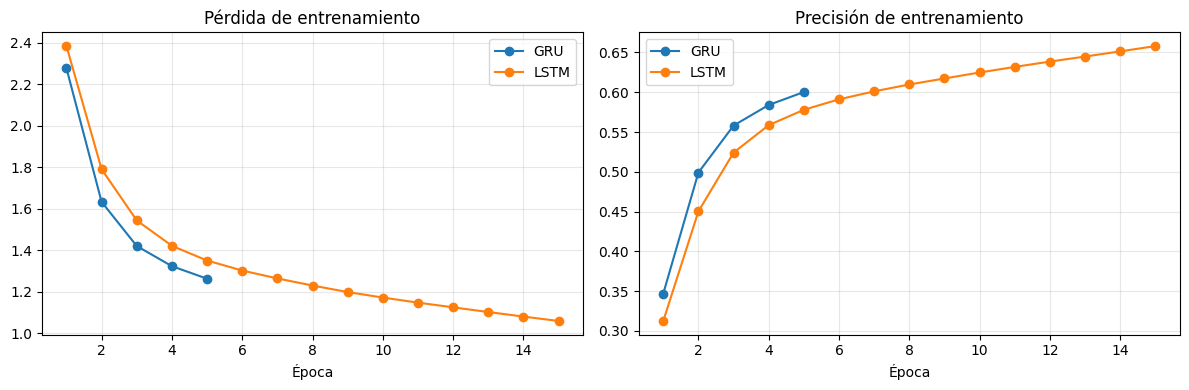

Modelo y resultados guardados en /content/don_quijote_lstm_15_epocas.zip


In [45]:
# @title Continuar LSTM hasta 15 épocas (sin reiniciar pesos)
if 'historial_lstm_total' not in globals():
    historial_lstm_total = {k: list(v) for k, v in historial_lstm.history.items()}
epocas_actuales = len(historial_lstm_total['loss'])
if epocas_actuales < 15:
    inicio_extra = time.perf_counter()
    historia_extra = modelo_lstm.fit(training_data, initial_epoch=epocas_actuales, epochs=15, shuffle=False)
    for clave, valores in historia_extra.history.items():
        historial_lstm_total.setdefault(clave, []).extend(valores)
    print(f'Tiempo adicional: {time.perf_counter() - inicio_extra:.1f} segundos')
else:
    print('La LSTM ya completó las 15 épocas.')
generador_lstm.set_weights(modelo_lstm.get_weights())
comparacion_15 = pd.concat([comparacion.copy(), pd.DataFrame([{'Modelo': 'LSTM (extendida)', 'Parametros': modelo_lstm.count_params(), 'Epocas': len(historial_lstm_total['loss']), 'Perdida_entrenamiento': historial_lstm_total['loss'][-1], 'Precision_entrenamiento': historial_lstm_total['sparse_categorical_accuracy'][-1]}])], ignore_index=True)
display(comparacion_15)
print('Métricas de entrenamiento. GRU 5 épocas frente a LSTM 5 y 15; presupuestos distintos, sin evaluación de generalización.')
ejemplo_lstm_15 = generar_lstm(frase_comparacion, temperatura, max_length, semilla)
print(f'Temperatura={temperatura}; semilla={semilla}; longitud={max_length}')
print('\nGRU 5 épocas:\n' + ejemplo_gru)
print('\nLSTM 5 épocas:\n' + ejemplo_lstm)
print('\nLSTM 15 épocas:\n' + ejemplo_lstm_15)
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, metrica, titulo in zip(ejes, ['loss', 'sparse_categorical_accuracy'], ['Pérdida de entrenamiento', 'Precisión de entrenamiento']):
    eje.plot(range(1, len(model.history.history[metrica])+1), model.history.history[metrica], marker='o', label='GRU')
    eje.plot(range(1, len(historial_lstm_total[metrica])+1), historial_lstm_total[metrica], marker='o', label='LSTM')
    eje.set(xlabel='Época', title=titulo)
    eje.legend()
    eje.grid(alpha=0.3)
fig.tight_layout()
plt.show()
carpeta_15 = Path('/content/don_quijote_lstm_15_epocas')
carpeta_15.mkdir(exist_ok=True)
modelo_lstm.save(carpeta_15 / 'modelo_lstm_15.keras')
(carpeta_15 / 'vocabulario.json').write_text(json.dumps(tokens, ensure_ascii=False), encoding='utf-8')
(carpeta_15 / 'historial_lstm_15.json').write_text(json.dumps(historial_lstm_total), encoding='utf-8')
comparacion_15.to_csv(carpeta_15 / 'comparacion.csv', index=False)
(carpeta_15 / 'ejemplos.txt').write_text(f'Temperatura={temperatura}; semilla={semilla}\nGRU 5 épocas:\n{ejemplo_gru}\n\nLSTM 5 épocas:\n{ejemplo_lstm}\n\nLSTM 15 épocas:\n{ejemplo_lstm_15}', encoding='utf-8')
fig.savefig(carpeta_15 / 'curvas_entrenamiento.png', dpi=160)
shutil.make_archive('/content/don_quijote_lstm_15_epocas', 'zip', carpeta_15)
print('Modelo y resultados guardados en /content/don_quijote_lstm_15_epocas.zip')


### Sequence-to-sequence learning

#### English-to-Spanish translation

In [ ]:
import pathlib

zip_path = keras.utils.get_file(
    origin=(
        "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
    ),
    fname="spa-eng",
    extract=True,
)
text_path = pathlib.Path(zip_path) / "spa-eng" / "spa.txt"

In [ ]:
with open(text_path) as f:
    lines = f.read().split("\n")[:-1]
text_pairs = []
for line in lines:
    english, spanish = line.split("\t")
    spanish = "[start] " + spanish + " [end]"
    text_pairs.append((english, spanish))

In [ ]:
import random
random.choice(text_pairs)

In [ ]:
import random

random.shuffle(text_pairs)
val_samples = int(0.15 * len(text_pairs))
train_samples = len(text_pairs) - 2 * val_samples
train_pairs = text_pairs[:train_samples]
val_pairs = text_pairs[train_samples : train_samples + val_samples]
test_pairs = text_pairs[train_samples + val_samples :]

In [ ]:
import string
import re

strip_chars = string.punctuation + "¿"
strip_chars = strip_chars.replace("[", "")
strip_chars = strip_chars.replace("]", "")

def custom_standardization(input_string):
    lowercase = tf.strings.lower(input_string)
    return tf.strings.regex_replace(
        lowercase, f"[{re.escape(strip_chars)}]", ""
    )

vocab_size = 15000
sequence_length = 20

english_tokenizer = layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length,
)
spanish_tokenizer = layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length + 1,
    standardize=custom_standardization,
)
train_english_texts = [pair[0] for pair in train_pairs]
train_spanish_texts = [pair[1] for pair in train_pairs]
english_tokenizer.adapt(train_english_texts)
spanish_tokenizer.adapt(train_spanish_texts)

In [ ]:
batch_size = 64

# Pre-tokenizamos los textos utilizando directamente los tokenizadores fuera de tf.data
# para evitar conflictos entre el grafo de TensorFlow y el backend de JAX
train_eng_tokenized = english_tokenizer(train_english_texts)
train_spa_tokenized = spanish_tokenizer(train_spanish_texts)

val_eng_texts = [pair[0] for pair in val_pairs]
val_spa_texts = [pair[1] for pair in val_pairs]
val_eng_tokenized = english_tokenizer(val_eng_texts)
val_spa_tokenized = spanish_tokenizer(val_spa_texts)

def format_dataset(eng_tokens, spa_tokens):
    features = {
        "english": eng_tokens,
        "spanish": spa_tokens[:, :-1]
    }
    labels = spa_tokens[:, 1:]
    sample_weights = labels != 0
    return features, labels, sample_weights

def make_dataset(eng_tokens, spa_tokens):
    dataset = tf.data.Dataset.from_tensor_slices((eng_tokens, spa_tokens))
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(format_dataset, num_parallel_calls=4)
    return dataset.shuffle(2048).cache()

train_ds = make_dataset(train_eng_tokenized, train_spa_tokenized)
val_ds = make_dataset(val_eng_tokenized, val_spa_tokenized)

In [ ]:
inputs, targets, sample_weights = next(iter(train_ds))
print(inputs["english"].shape)

In [ ]:
print(inputs["spanish"].shape)

In [ ]:
print(targets.shape)

In [ ]:
print(sample_weights.shape)

#### Sequence-to-sequence learning with RNNs

In [ ]:
embed_dim = 256
hidden_dim = 1024

source = keras.Input(shape=(None,), dtype="int32", name="english")
x = layers.Embedding(vocab_size, embed_dim)(source)
rnn_layer = layers.GRU(hidden_dim)
rnn_layer = layers.Bidirectional(rnn_layer, merge_mode="sum")
encoder_output = rnn_layer(x)

In [ ]:
target = keras.Input(shape=(None,), dtype="int32", name="spanish")
x = layers.Embedding(vocab_size, embed_dim)(target)
rnn_layer = layers.GRU(hidden_dim, return_sequences=True)
x = rnn_layer(x, initial_state=encoder_output)
x = layers.Dropout(0.5)(x)
target_predictions = layers.Dense(vocab_size, activation="softmax")(x)
seq2seq_rnn = keras.Model([source, target], target_predictions)

In [ ]:
seq2seq_rnn.summary(line_length=80)

In [ ]:
seq2seq_rnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"],
)
seq2seq_rnn.fit(train_ds, epochs=5, validation_data=val_ds)

In [ ]:
import numpy as np

spa_vocab = spanish_tokenizer.get_vocabulary()
spa_index_lookup = dict(zip(range(len(spa_vocab)), spa_vocab))

def generate_translation(input_sentence):
    tokenized_input_sentence = english_tokenizer([input_sentence])
    decoded_sentence = "[start]"
    for i in range(sequence_length):
        tokenized_target_sentence = spanish_tokenizer([decoded_sentence])
        inputs = [tokenized_input_sentence, tokenized_target_sentence]
        next_token_predictions = seq2seq_rnn.predict(inputs, verbose=0)
        sampled_token_index = np.argmax(next_token_predictions[0, i, :])
        sampled_token = spa_index_lookup[sampled_token_index]
        decoded_sentence += " " + sampled_token
        if sampled_token == "[end]":
            break
    return decoded_sentence

test_eng_texts = [pair[0] for pair in test_pairs]
for _ in range(5):
    input_sentence = random.choice(test_eng_texts)
    print("-")
    print(input_sentence)
    print(generate_translation(input_sentence))